<a href="https://colab.research.google.com/github/Sarah-Jack05/encs4380-dynamics--Mazion-/blob/main/Module4_Simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

        ENCS4380 - GUESS THE SENSOR

You will observe a noisy sensor response.
Your task is to identify the sensor type
and estimate its parameters.

Scoring:
  First-order  -> K + tau
  Second-order -> zeta + omega_n
  Each parameter within 10% = 50 points
  Maximum per round = 100 points


Enter number of rounds (1-5): 1

ROUND 1 / 1

Input type: STEP



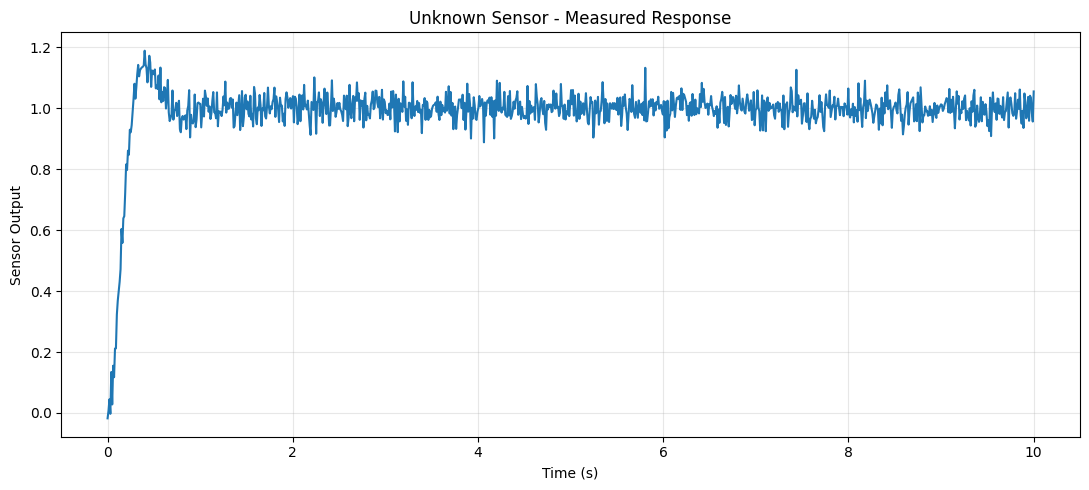


Hint: Look for oscillation and overshoot.

Guess sensor type (first/second): second
Estimate zeta: 3.05
Estimate omega_n: 3.33

------------------------------------------------------------
✓ SENSOR TYPE: CORRECT

zeta error: 497.52%
  ✗ More than 10%
omega_n error: 62.84%
  ✗ More than 10%

------------------------------------------------------------
TRUE SENSOR PARAMETERS
------------------------------------------------------------
Sensor type: SECOND-ORDER
Damping type = underdamped
zeta = 0.5104
omega_n = 8.9621 rad/s
Overshoot = 15.49%

ROUND SCORE = 0/100


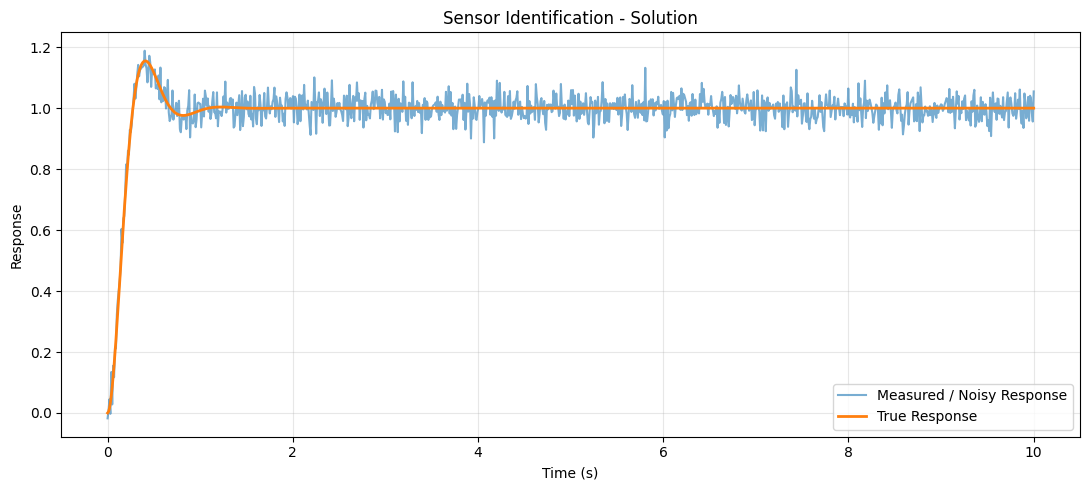

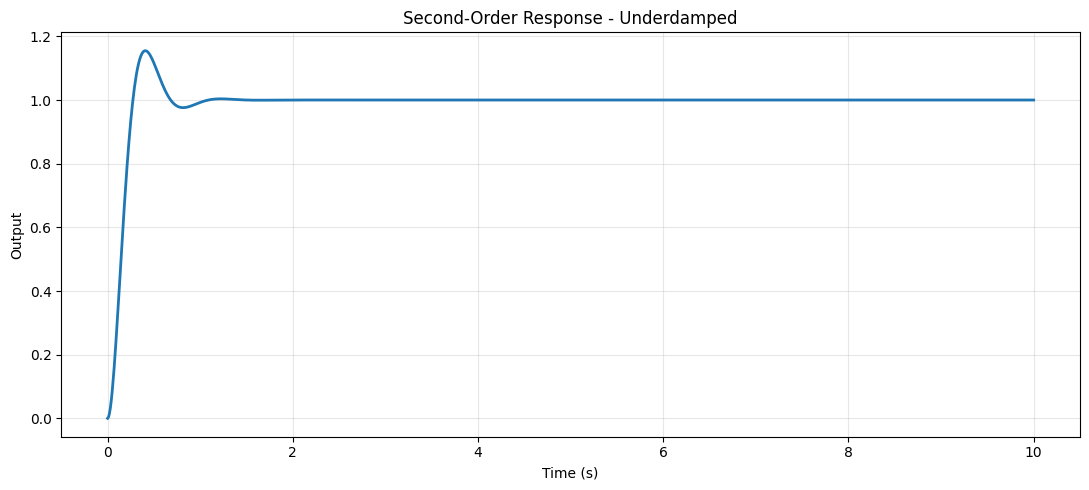


------------------------------------------------------------
SECOND-ORDER CHARACTERISTICS
------------------------------------------------------------
Damping ratio (zeta):     0.5104
Natural frequency:        8.9621 rad/s
Damping type:             Underdamped
Percent overshoot:        15.49%
Pole 1:                   (-4.574636953812009+7.706659576685778j)
Pole 2:                   (-4.574636953812009-7.706659576685778j)


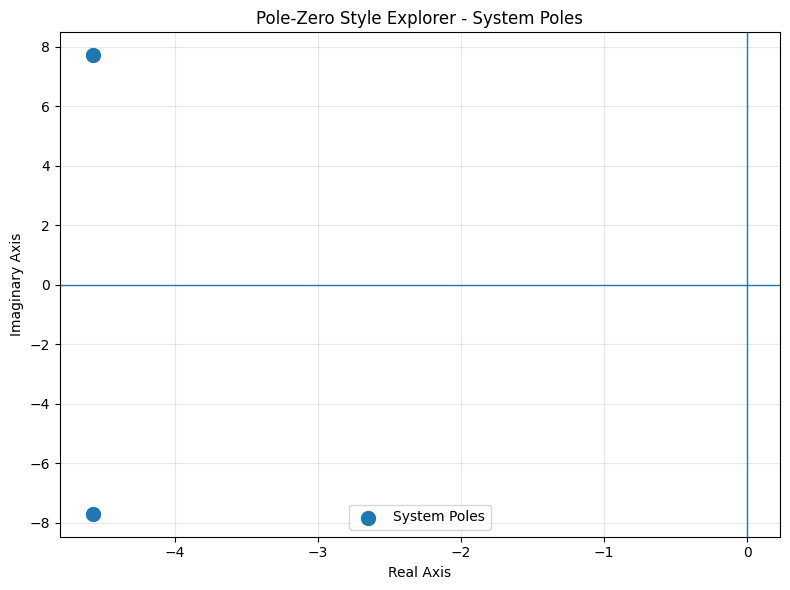


                    FINAL RESULTS

Round 1: 0/100

Total Score: 0/100
Average Score: 0.00/100

Keep practicing the dynamic characteristics.

                    GAME COMPLETE


In [18]:
# ============================================================
# ENCS4380 - Homework 1
# MODULE 4: GUESS THE SENSOR
# Complete Google Colab Simulation
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------
np.random.seed()


# ============================================================
# MODULE 1 CALCULATIONS
# ============================================================

def calculate_step_response(K, tau, t, A=1.0):

    if tau <= 0:
        raise ValueError("Time constant must be positive.")

    return K * A * (1 - np.exp(-np.asarray(t) / tau))


# ============================================================
# MODULE 3 CALCULATIONS
# Second-Order System
# ============================================================

def calculate_damping_type(zeta):

    if zeta <= 0:
        raise ValueError("Damping ratio must be positive.")

    if zeta < 1:
        return "Underdamped"

    elif np.isclose(zeta, 1.0):
        return "Critically Damped"

    else:
        return "Overdamped"


def calculate_overshoot(zeta):

    if zeta < 1:
        return (
            np.exp(
                (-np.pi * zeta) /
                np.sqrt(1 - zeta**2)
            ) * 100
        )

    return 0.0


def calculate_second_order_step_response(
    K,
    zeta,
    omega_n,
    t,
    A=1.0
):

    if zeta <= 0:
        raise ValueError("Damping ratio must be positive.")

    if omega_n <= 0:
        raise ValueError("Natural frequency must be positive.")

    t = np.asarray(t)

    # --------------------------------------------------------
    # Underdamped
    # --------------------------------------------------------
    if zeta < 1:

        omega_d = (
            omega_n *
            np.sqrt(1 - zeta**2)
        )

        return K * A * (
            1
            -
            np.exp(-zeta * omega_n * t)
            *
            (
                np.cos(omega_d * t)
                +
                (
                    zeta /
                    np.sqrt(1 - zeta**2)
                )
                *
                np.sin(omega_d * t)
            )
        )

    # --------------------------------------------------------
    # Critically damped
    # --------------------------------------------------------
    elif np.isclose(zeta, 1.0):

        return K * A * (
            1
            -
            np.exp(-omega_n * t)
            *
            (1 + omega_n * t)
        )

    # --------------------------------------------------------
    # Overdamped
    # --------------------------------------------------------
    else:

        alpha = np.sqrt(zeta**2 - 1)

        return K * A * (
            1
            -
            (
                (zeta + alpha)
                *
                np.exp(
                    -omega_n *
                    (zeta - alpha) *
                    t
                )

                -

                (zeta - alpha)
                *
                np.exp(
                    -omega_n *
                    (zeta + alpha) *
                    t
                )
            )
            /
            (2 * alpha)
        )


# ============================================================
# POLES
# ============================================================

def calculate_poles(zeta, omega_n):

    if zeta <= 0:
        raise ValueError("Damping ratio must be positive.")

    if omega_n <= 0:
        raise ValueError("Natural frequency must be positive.")

    if zeta < 1:

        real_part = -zeta * omega_n

        imag_part = (
            omega_n *
            np.sqrt(1 - zeta**2)
        )

        return (
            complex(real_part, imag_part),
            complex(real_part, -imag_part)
        )

    elif np.isclose(zeta, 1.0):

        pole = -omega_n

        return pole, pole

    else:

        alpha = np.sqrt(zeta**2 - 1)

        p1 = (
            -zeta * omega_n
            +
            omega_n * alpha
        )

        p2 = (
            -zeta * omega_n
            -
            omega_n * alpha
        )

        return p1, p2


# ============================================================
# MODULE 4
# RANDOM SENSOR GENERATION
# ============================================================

def generate_random_sensor():

    sensor_type = np.random.choice(
        ["first_order", "second_order"]
    )

    # --------------------------------------------------------
    # First-Order Sensor
    # --------------------------------------------------------
    if sensor_type == "first_order":

        K = np.random.uniform(1, 5)

        tau = np.random.uniform(0.5, 5)

        return {
            "type": "first_order",
            "K": K,
            "tau": tau
        }

    # --------------------------------------------------------
    # Second-Order Sensor
    # --------------------------------------------------------
    else:

        damping_type = np.random.choice(
            [
                "underdamped",
                "critically_damped",
                "overdamped"
            ]
        )

        if damping_type == "underdamped":

            zeta = np.random.uniform(0.2, 0.95)

        elif damping_type == "critically_damped":

            zeta = 1.0

        else:

            zeta = np.random.uniform(1.05, 2.0)

        omega_n = np.random.uniform(1, 10)

        return {
            "type": "second_order",
            "damping_type": damping_type,
            "zeta": zeta,
            "omega_n": omega_n
        }


# ============================================================
# TRUE SENSOR RESPONSE
# ============================================================

def generate_true_response(
    sensor,
    t,
    A=1.0,
    input_type="step",
    frequency=1.0
):

    # --------------------------------------------------------
    # First Order
    # --------------------------------------------------------

    if sensor["type"] == "first_order":

        if input_type == "step":

            return calculate_step_response(
                sensor["K"],
                sensor["tau"],
                t,
                A
            )

        elif input_type == "sine":

            omega = 2 * np.pi * frequency

            M = (
                1 /
                np.sqrt(
                    1 +
                    (omega * sensor["tau"])**2
                )
            )

            phi = np.arctan(
                omega * sensor["tau"]
            )

            return (
                sensor["K"]
                *
                A
                *
                M
                *
                np.sin(
                    omega * t - phi
                )
            )

        else:

            raise ValueError(
                "Invalid input type."
            )

    # --------------------------------------------------------
    # Second Order
    # --------------------------------------------------------

    elif sensor["type"] == "second_order":

        return calculate_second_order_step_response(
            1.0,
            sensor["zeta"],
            sensor["omega_n"],
            t,
            A
        )

    else:

        raise ValueError(
            "Invalid sensor type."
        )


# ============================================================
# ADD MEASUREMENT NOISE
# ============================================================

def add_noise(
    response,
    noise_level=0.02
):

    response = np.asarray(response)

    noise_std = (
        noise_level *
        np.max(np.abs(response))
    )

    noise = np.random.normal(
        0,
        noise_std,
        size=response.shape
    )

    return response + noise


# ============================================================
# GUESS ERROR
# ============================================================

def calculate_guess_error(
    true_value,
    guessed_value
):

    if true_value == 0:

        raise ValueError(
            "True value cannot be zero."
        )

    return (
        abs(true_value - guessed_value)
        /
        abs(true_value)
        *
        100
    )


# ============================================================
# SCORE
# ============================================================

def calculate_score(errors):

    score = 0

    for error in errors.values():

        if error <= 10:

            score += 50

    return score


# ============================================================
# EVALUATE GUESS
# ============================================================

def evaluate_guess(
    sensor,
    guessed_parameters
):

    if sensor["type"] == "first_order":

        errors = {

            "K":
            calculate_guess_error(
                sensor["K"],
                guessed_parameters["K"]
            ),

            "tau":
            calculate_guess_error(
                sensor["tau"],
                guessed_parameters["tau"]
            )
        }

    elif sensor["type"] == "second_order":

        errors = {

            "zeta":
            calculate_guess_error(
                sensor["zeta"],
                guessed_parameters["zeta"]
            ),

            "omega_n":
            calculate_guess_error(
                sensor["omega_n"],
                guessed_parameters["omega_n"]
            )
        }

    else:

        raise ValueError(
            "Invalid sensor type."
        )

    score = calculate_score(errors)

    return errors, score


# ============================================================
# HINT
# ============================================================

def generate_hint(
    sensor,
    input_type="step"
):

    if sensor["type"] == "first_order":

        if input_type == "step":

            return (
                "Hint: At t = tau, "
                "the response reaches about "
                "63.2% of its final value."
            )

        else:

            return (
                "Hint: Amplitude ratio and "
                "phase lag depend on omega and tau."
            )

    else:

        if sensor["damping_type"] == "underdamped":

            return (
                "Hint: Look for oscillation and overshoot."
            )

        elif sensor["damping_type"] == "critically_damped":

            return (
                "Hint: The response has no overshoot "
                "and reaches the final value quickly."
            )

        else:

            return (
                "Hint: There is no oscillation, "
                "but the response is slower than critical damping."
            )


# ============================================================
# CREATE ONE ROUND
# ============================================================

def generate_new_round(
    duration=10,
    points=1000,
    noise_level=0.02
):

    sensor = generate_random_sensor()

    input_type = "step"

    frequency = None

    if sensor["type"] == "first_order":

        input_type = np.random.choice(
            ["step", "sine"]
        )

        if input_type == "sine":

            frequency = np.random.uniform(
                0.1,
                2.0
            )

    t = np.linspace(
        0,
        duration,
        points
    )

    true_response = generate_true_response(
        sensor,
        t,
        input_type=input_type,
        frequency=(
            frequency
            if frequency is not None
            else 1.0
        )
    )

    noisy_response = add_noise(
        true_response,
        noise_level
    )

    return (
        sensor,
        t,
        true_response,
        noisy_response,
        input_type,
        frequency
    )


# ============================================================
# ANALYZE RESPONSE
# ============================================================

def analyze_response(
    sensor,
    t,
    true_response,
    input_type,
    frequency
):

    results = {}

    # --------------------------------------------------------
    # First Order
    # --------------------------------------------------------

    if sensor["type"] == "first_order":

        K = sensor["K"]
        tau = sensor["tau"]

        final_value = K

        target_632 = (
            final_value * 0.6321
        )

        # Find closest point to 63.2%
        index_632 = np.argmin(
            np.abs(
                true_response -
                target_632
            )
        )

        measured_tau = t[index_632]

        results["final_value"] = final_value
        results["tau"] = tau
        results["measured_tau"] = measured_tau

        if input_type == "sine":

            omega = (
                2 *
                np.pi *
                frequency
            )

            M = (
                1 /
                np.sqrt(
                    1 +
                    (omega * tau)**2
                )
            )

            phase = (
                -np.degrees(
                    np.arctan(
                        omega * tau
                    )
                )
            )

            results["omega"] = omega
            results["amplitude_ratio"] = M
            results["phase_lag"] = phase

    # --------------------------------------------------------
    # Second Order
    # --------------------------------------------------------

    else:

        zeta = sensor["zeta"]

        omega_n = sensor["omega_n"]

        damping_type = (
            calculate_damping_type(zeta)
        )

        overshoot = (
            calculate_overshoot(zeta)
        )

        poles = calculate_poles(
            zeta,
            omega_n
        )

        results["zeta"] = zeta
        results["omega_n"] = omega_n
        results["damping_type"] = damping_type
        results["overshoot"] = overshoot
        results["poles"] = poles

    return results


# ============================================================
# PLOT OBSERVED SIGNAL
# ============================================================

def plot_observed_signal(
    t,
    noisy_response,
    input_type
):

    plt.figure(
        figsize=(11, 5)
    )

    plt.plot(
        t,
        noisy_response,
        linewidth=1.5
    )

    plt.xlabel(
        "Time (s)"
    )

    plt.ylabel(
        "Sensor Output"
    )

    plt.title(
        "Unknown Sensor - Measured Response"
    )

    plt.grid(
        True,
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


# ============================================================
# PLOT TRUE RESPONSE AFTER GUESS
# ============================================================

def plot_solution(
    t,
    true_response,
    noisy_response,
    sensor,
    input_type,
    frequency
):

    plt.figure(
        figsize=(11, 5)
    )

    plt.plot(
        t,
        noisy_response,
        label="Measured / Noisy Response",
        alpha=0.6
    )

    plt.plot(
        t,
        true_response,
        label="True Response",
        linewidth=2
    )

    plt.xlabel(
        "Time (s)"
    )

    plt.ylabel(
        "Response"
    )

    plt.title(
        "Sensor Identification - Solution"
    )

    plt.grid(
        True,
        alpha=0.3
    )

    plt.legend()

    plt.tight_layout()

    plt.show()


# ============================================================
# PLOT POLES
# ============================================================

def plot_poles(
    sensor
):

    if sensor["type"] != "second_order":

        return

    zeta = sensor["zeta"]

    omega_n = sensor["omega_n"]

    p1, p2 = calculate_poles(
        zeta,
        omega_n
    )

    plt.figure(
        figsize=(8, 6)
    )

    plt.axhline(
        0,
        linewidth=1
    )

    plt.axvline(
        0,
        linewidth=1
    )

    if np.iscomplex(p1):

        plt.scatter(
            [p1.real, p2.real],
            [p1.imag, p2.imag],
            s=100,
            label="System Poles"
        )

    else:

        plt.scatter(
            [p1, p2],
            [0, 0],
            s=100,
            label="System Poles"
        )

    plt.xlabel(
        "Real Axis"
    )

    plt.ylabel(
        "Imaginary Axis"
    )

    plt.title(
        "Pole-Zero Style Explorer - System Poles"
    )

    plt.grid(
        True,
        alpha=0.3
    )

    plt.legend()

    plt.tight_layout()

    plt.show()


# ============================================================
# PLOT SECOND-ORDER CHARACTERISTICS
# ============================================================

def plot_second_order_characteristics(
    sensor,
    t,
    true_response
):

    zeta = sensor["zeta"]

    omega_n = sensor["omega_n"]

    damping_type = (
        calculate_damping_type(zeta)
    )

    overshoot = (
        calculate_overshoot(zeta)
    )

    plt.figure(
        figsize=(11, 5)
    )

    plt.plot(
        t,
        true_response,
        linewidth=2
    )

    plt.xlabel(
        "Time (s)"
    )

    plt.ylabel(
        "Output"
    )

    plt.title(
        f"Second-Order Response - {damping_type}"
    )

    plt.grid(
        True,
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()

    print()
    print("-" * 60)
    print("SECOND-ORDER CHARACTERISTICS")
    print("-" * 60)

    print(
        f"Damping ratio (zeta):     {zeta:.4f}"
    )

    print(
        f"Natural frequency:        {omega_n:.4f} rad/s"
    )

    print(
        f"Damping type:             {damping_type}"
    )

    print(
        f"Percent overshoot:        {overshoot:.2f}%"
    )

    p1, p2 = calculate_poles(
        zeta,
        omega_n
    )

    print(
        f"Pole 1:                   {p1}"
    )

    print(
        f"Pole 2:                   {p2}"
    )


# ============================================================
# MAIN GAME
# ============================================================

print("=" * 70)
print("        ENCS4380 - GUESS THE SENSOR")
print("=" * 70)

print()
print("You will observe a noisy sensor response.")
print("Your task is to identify the sensor type")
print("and estimate its parameters.")
print()
print("Scoring:")
print("  First-order  -> K + tau")
print("  Second-order -> zeta + omega_n")
print("  Each parameter within 10% = 50 points")
print("  Maximum per round = 100 points")
print()
print("=" * 70)


# ============================================================
# NUMBER OF ROUNDS
# ============================================================

try:

    rounds = int(
        input(
            "\nEnter number of rounds "
            "(1-5): "
        )
    )

except:

    rounds = 1

rounds = max(
    1,
    min(
        rounds,
        5
    )
)


# ============================================================
# RUN GAME
# ============================================================

total_score = 0

all_scores = []

for round_number in range(
    1,
    rounds + 1
):

    print()
    print("=" * 70)

    print(
        f"ROUND {round_number} / {rounds}"
    )

    print("=" * 70)

    (
        sensor,
        t,
        true_response,
        noisy_response,
        input_type,
        frequency
    ) = generate_new_round(
        duration=10,
        points=1000,
        noise_level=0.03
    )

    # --------------------------------------------------------
    # Show observation
    # --------------------------------------------------------

    print()

    if input_type == "step":

        print(
            "Input type: STEP"
        )

    else:

        print(
            f"Input type: SINE"
        )

        print(
            f"Frequency: {frequency:.3f} Hz"
        )

    print()

    plot_observed_signal(
        t,
        noisy_response,
        input_type
    )

    # --------------------------------------------------------
    # Hint
    # --------------------------------------------------------

    print()

    print(
        generate_hint(
            sensor,
            input_type
        )
    )

    print()

    # --------------------------------------------------------
    # Guess sensor type
    # --------------------------------------------------------

    guess_type = input(
        "Guess sensor type "
        "(first/second): "
    ).strip().lower()

    if (
        guess_type.startswith("first")
        or guess_type == "1"
    ):

        guessed_type = "first_order"

    elif (
        guess_type.startswith("second")
        or guess_type == "2"
    ):

        guessed_type = "second_order"

    else:

        print(
            "Invalid input. Assuming first-order."
        )

        guessed_type = "first_order"

    # --------------------------------------------------------
    # Parameter guesses
    # --------------------------------------------------------

    guessed_parameters = {}

    if guessed_type == "first_order":

        try:

            guessed_K = float(
                input(
                    "Estimate K: "
                )
            )

            guessed_tau = float(
                input(
                    "Estimate tau: "
                )
            )

        except:

            print(
                "Invalid values. Using 1."
            )

            guessed_K = 1.0
            guessed_tau = 1.0

        guessed_parameters["K"] = (
            guessed_K
        )

        guessed_parameters["tau"] = (
            guessed_tau
        )

    else:

        try:

            guessed_zeta = float(
                input(
                    "Estimate zeta: "
                )
            )

            guessed_omega_n = float(
                input(
                    "Estimate omega_n: "
                )
            )

        except:

            print(
                "Invalid values. Using 0.5 and 2."
            )

            guessed_zeta = 0.5
            guessed_omega_n = 2.0

        guessed_parameters["zeta"] = (
            guessed_zeta
        )

        guessed_parameters["omega_n"] = (
            guessed_omega_n
        )

    # --------------------------------------------------------
    # Check Type
    # --------------------------------------------------------

    print()
    print("-" * 60)

    if guessed_type == sensor["type"]:

        print(
            "✓ SENSOR TYPE: CORRECT"
        )

    else:

        print(
            "✗ SENSOR TYPE: WRONG"
        )

    # --------------------------------------------------------
    # Evaluate Guess
    # --------------------------------------------------------

    if guessed_type == sensor["type"]:

        errors, round_score = (
            evaluate_guess(
                sensor,
                guessed_parameters
            )
        )

    else:

        errors = {}

        round_score = 0

    # --------------------------------------------------------
    # Display Errors
    # --------------------------------------------------------

    print()

    if errors:

        for parameter, error in (
            errors.items()
        ):

            print(
                f"{parameter} error: "
                f"{error:.2f}%"
            )

            if error <= 10:

                print(
                    "  ✓ Within 10%"
                )

            else:

                print(
                    "  ✗ More than 10%"
                )

    # --------------------------------------------------------
    # Reveal Solution
    # --------------------------------------------------------

    print()
    print("-" * 60)
    print("TRUE SENSOR PARAMETERS")
    print("-" * 60)

    if sensor["type"] == "first_order":

        print(
            "Sensor type: FIRST-ORDER"
        )

        print(
            f"K = {sensor['K']:.4f}"
        )

        print(
            f"tau = {sensor['tau']:.4f} s"
        )

        if input_type == "sine":

            print(
                f"Frequency = "
                f"{frequency:.4f} Hz"
            )

    else:

        print(
            "Sensor type: SECOND-ORDER"
        )

        print(
            f"Damping type = "
            f"{sensor['damping_type']}"
        )

        print(
            f"zeta = "
            f"{sensor['zeta']:.4f}"
        )

        print(
            f"omega_n = "
            f"{sensor['omega_n']:.4f} rad/s"
        )

        print(
            f"Overshoot = "
            f"{calculate_overshoot(sensor['zeta']):.2f}%"
        )

    print()

    print(
        f"ROUND SCORE = "
        f"{round_score}/100"
    )

    total_score += round_score

    all_scores.append(
        round_score
    )

    # --------------------------------------------------------
    # Reveal Graph
    # --------------------------------------------------------

    plot_solution(
        t,
        true_response,
        noisy_response,
        sensor,
        input_type,
        frequency
    )

    # --------------------------------------------------------
    # Second-Order Extra Analysis
    # --------------------------------------------------------

    if sensor["type"] == "second_order":

        plot_second_order_characteristics(
            sensor,
            t,
            true_response
        )

        plot_poles(
            sensor
        )

    # --------------------------------------------------------
    # First-Order Extra Analysis
    # --------------------------------------------------------

    else:

        tau = sensor["tau"]

        final_value = sensor["K"]

        target_632 = (
            0.6321 *
            final_value
        )

        plt.figure(
            figsize=(11, 5)
        )

        plt.plot(
            t,
            true_response,
            linewidth=2,
            label="True Response"
        )

        plt.axhline(
            target_632,
            linestyle="--",
            label="63.2%"
        )

        plt.axvline(
            tau,
            linestyle="--",
            label=f"tau = {tau:.3f} s"
        )

        plt.xlabel(
            "Time (s)"
        )

        plt.ylabel(
            "Output"
        )

        plt.title(
            "First-Order Identification: 63.2% Time Constant"
        )

        plt.grid(
            True,
            alpha=0.3
        )

        plt.legend()

        plt.tight_layout()

        plt.show()

# ============================================================
# FINAL SCORE
# ============================================================

average_score = (
    total_score / rounds
)

print()
print("=" * 70)
print("                    FINAL RESULTS")
print("=" * 70)

print()

for i, score in enumerate(
    all_scores,
    start=1
):

    print(
        f"Round {i}: {score}/100"
    )

print()

print(
    f"Total Score: "
    f"{total_score}/{rounds * 100}"
)

print(
    f"Average Score: "
    f"{average_score:.2f}/100"
)

print()

if average_score >= 80:

    print(
        "🏆 Excellent sensor identification!"
    )

elif average_score >= 60:

    print(
        "✓ Good performance!"
    )

else:

    print(
        "Keep practicing the dynamic characteristics."
    )

print()
print("=" * 70)
print("                    GAME COMPLETE")
print("=" * 70)